# 3. Does the idea hold up?

The proposed fix is a check that a support agent runs before escalating a ticket. Before building it, I
tested two assumptions it could have rested on, and then estimated how much a working check might help.

Both assumptions turned out to be wrong, and that changed the design.

## Setting up

Same setup as notebook 1.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../backend/data/rideops_support_tickets.csv")

for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at"]:
    df[col] = pd.to_datetime(df[col])

# The data was pulled at the end of 30 Sep 2026. We treat that as "now".
now = pd.Timestamp("2026-09-30 23:59")

df["escalated"] = df["escalated_to_eng"] == "Yes"
df["is_open"] = df["status"] != "Closed"
df["reopened"] = df["reopen_count"] > 0

# "Bounced" = sent to engineering, but engineering did not fix it
df["eng_outcome"] = df["eng_outcome"].fillna("")
df["bounced"] = df["escalated"] & (df["eng_outcome"] != "Fixed")

df["hours_to_close"] = (df["final_closed_at"] - df["created_at"]).dt.total_seconds() / 3600

end_time = df["final_closed_at"].fillna(now)
df["age_hours"] = (end_time - df["created_at"]).dt.total_seconds() / 3600

# Replace numbers with N, so similar problems get the same name
df["issue_type"] = df["description"].str.replace(r"\d+", "N", regex=True)

print("Tickets:", len(df))

Tickets: 1444


## Can we predict which escalations will come back?

My first idea was a tool that warns an agent when a ticket looks likely to bounce. For that to be
useful, past tickets have to say something about future ones.

To test it fairly, I split by time. Rules are learned from escalations raised in July and August, then
scored on September, which the rules have not seen. A rule flags a ticket when 60% or more of its group
came back in the learning period.

In [2]:
sent_to_eng = df[df["escalated"]]

learn = sent_to_eng[sent_to_eng["created_at"] < "2026-09-01"]
test = sent_to_eng[sent_to_eng["created_at"] >= "2026-09-01"]

# If we flag every ticket, how often are we right?
normal_rate = test["bounced"].mean()

print("Tickets to learn from:", len(learn))
print("Tickets to test on:", len(test))
print("In the test tickets,", round(normal_rate * 100), "% came back anyway")

Tickets to learn from: 297
Tickets to test on: 189
In the test tickets, 59 % came back anyway


The 59% is the bar to beat. More than half of September's escalations came back regardless, so a rule
only earns its place if the tickets it flags come back clearly more often than that.

I tried four groupings: type of problem, category, agent, and type of problem together with agent.

In [3]:
# One more column: the type of problem and the agent together
learn = learn.assign(issue_and_agent=learn["issue_type"] + " | " + learn["assigned_agent"])
test = test.assign(issue_and_agent=test["issue_type"] + " | " + test["assigned_agent"])

results = []

for col in ["issue_type", "category", "assigned_agent", "issue_and_agent"]:
    # How often did each group come back in July and August?
    past = learn.groupby(col)["bounced"].agg(["mean", "count"])

    # Keep groups with at least 3 tickets where 60% or more came back
    risky_groups = past[(past["count"] >= 3) & (past["mean"] >= 0.6)].index

    # Flag the September tickets that belong to those groups
    flagged = test[test[col].isin(risky_groups)]

    results.append({
        "rule": "same " + col,
        "tickets_flagged": len(flagged),
        "flagged_that_came_back_%": round(flagged["bounced"].mean() * 100),
    })

results = pd.DataFrame(results)
results

,rule,tickets_flagged,flagged_that_came_back_%
0,same issue_type,62,56
1,same category,54,57
2,same assigned_agent,69,65
3,same issue_and_agent,22,73


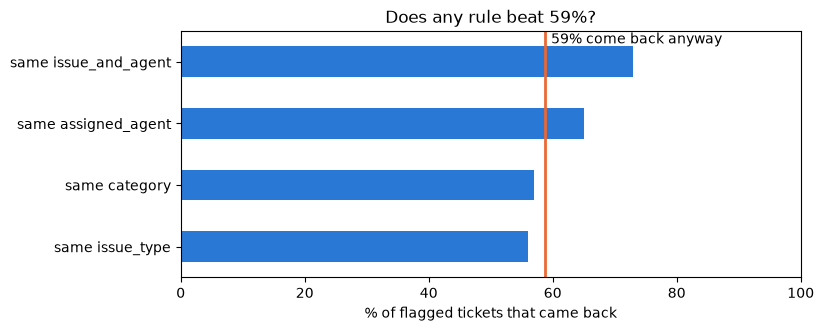

In [4]:
results.plot(kind="barh", x="rule", y="flagged_that_came_back_%", color="#2a78d6",
             legend=False, figsize=(8, 3.2), title="Does any rule beat 59%?")
plt.axvline(normal_rate * 100, color="#eb6834", linewidth=2)
plt.text(normal_rate * 100 + 1, 3.3, "59% come back anyway")
plt.xlim(0, 100)
plt.ylabel("")
plt.xlabel("% of flagged tickets that came back")
plt.show()

Grouping by type of problem gives 56% and by category 57%, both slightly worse than flagging everything.
By agent it is 65%, a small gain that is really the one agent from notebook 1. Type of problem and agent
together reaches 73%, but on only 22 tickets. That is too few to rely on, and it misses most of the
tickets that come back.

So the type of problem does not tell us which escalations will come back.

This is a test of simple rules only. With 189 test tickets, a larger model would be easy to fool, so I
did not build one.

## Can duplicates be caught automatically?

56 tickets were returned as duplicates of a known issue. A cheap way to catch those would be to warn the
agent whenever the same kind of problem was escalated in the previous seven days.

In [5]:
seen_recently = []

for index, row in test.iterrows():
    same_problem = sent_to_eng["issue_type"] == row["issue_type"]
    before_this = sent_to_eng["created_at"] < row["created_at"]
    within_7_days = sent_to_eng["created_at"] >= row["created_at"] - pd.Timedelta(days=7)

    earlier_tickets = sent_to_eng[same_problem & before_this & within_7_days]
    seen_recently.append(len(earlier_tickets) > 0)

test = test.copy()
test["seen_recently"] = seen_recently
test["is_duplicate"] = test["eng_outcome"] == "Duplicate of known issue"

warned = test[test["seen_recently"]]

print("Tickets we would warn on:", len(warned), "of", len(test))
print("Of those, really duplicates:", round(warned["is_duplicate"].mean() * 100), "%")
print("Duplicates among all test tickets:", round(test["is_duplicate"].mean() * 100), "%")

Tickets we would warn on: 129 of 189
Of those, really duplicates: 17 %
Duplicates among all test tickets: 14 %


The warning would fire on about two thirds of escalations and be right 17% of the time. With no rule at
all, 14% are duplicates. That is not worth an agent's attention.

### What these two results changed

The tool does not score or guess. More than half of escalations come back anyway, so the check runs on
every one of them. The checklist is built from the reasons engineering gives for sending tickets back.
Duplicates are handled by a list of known issues that engineering maintains.

One caveat: the data is made up. Real tickets have longer text and might be more predictable.

## If the check works, how much does it help?

This is a what-if on the same three months, not a measurement.

For each ticket that came back, I assume what would have happened with a good check:

| Why it came back | What happens instead | Time assumed |
|---|---|---|
| Settings problem, or a how-to question | Support solves it | Normal support time for that category |
| Not enough information, or could not reproduce | One clean trip to engineering | Normal time for a one-trip fix |
| Duplicate | Linked to the known issue | Unchanged |

No ticket is ever made slower than it really was.

These assumptions lean optimistic. A ticket the agent chose to escalate was probably harder than the
typical ticket support solves alone, and not every missing-information ticket would turn into a clean
one-trip fix. Showing a quarter, a half and all of them prevented is how I allow for that.

In [6]:
# Normal time for support to solve each category
support_time = df[~df["escalated"]].groupby("category")["hours_to_close"].median()

# Normal time for a fix that needed only one trip
one_trip_fixes = df[(df["eng_outcome"] == "Fixed") & (df["eng_handoffs"] == 1)]
one_trip_time = one_trip_fixes["hours_to_close"].median()
print("Normal time for a one-trip fix:", round(one_trip_time, 1), "hours")

# Start with the real time, then change it for tickets that came back
df["what_if_hours"] = df["age_hours"]

support_could_solve = df["eng_outcome"].isin(["Config issue - returned to L1", "Not a bug - how-to"])
df.loc[support_could_solve, "what_if_hours"] = df.loc[support_could_solve, "category"].map(support_time)

needs_one_trip = df["eng_outcome"].isin(["Insufficient info - returned to L1", "Not reproducible"])
df.loc[needs_one_trip, "what_if_hours"] = one_trip_time

# Never slower than what really happened
df["what_if_hours"] = df[["what_if_hours", "age_hours"]].min(axis=1)

df["hours_saved"] = df["age_hours"] - df["what_if_hours"]

Normal time for a one-trip fix: 56.8 hours


In [7]:
# Hours saved for each reason, if every one of them was prevented
came_back = df[df["bounced"]]
saved_by_reason = came_back.groupby("eng_outcome").agg(
    tickets=("ticket_id", "count"),
    hours_saved=("hours_saved", "sum"),
)
saved_by_reason.sort_values("hours_saved", ascending=False).round(0)

,tickets,hours_saved
eng_outcome,,
Config issue - returned to L1,84,10442.0
Insufficient info - returned to L1,89,6973.0
Not a bug - how-to,24,1410.0
Not reproducible,22,477.0
Duplicate of known issue,56,0.0


Nobody knows yet what share of these the check would really prevent, so I show three cases: a quarter,
a half, and all of them.

In [8]:
total_saved = df["hours_saved"].sum()
total_waiting = df["age_hours"].sum()

# Open tickets today, and the ones that would already be closed in the "what if"
open_now = df[df["is_open"]]
old_open = open_now[open_now["age_hours"] >= 48]
would_be_closed = open_now[open_now["what_if_hours"] < open_now["age_hours"]]
old_would_be_closed = old_open[old_open["what_if_hours"] < old_open["age_hours"]]

rows = []
for share in [0, 0.25, 0.5, 1.0]:
    rows.append({
        "check_stops": str(int(share * 100)) + "%",
        "open_over_48h": len(old_open) - share * len(old_would_be_closed),
        "all_open": len(open_now) - share * len(would_be_closed),
        "waiting_hours_saved": round(total_saved * share),
        "saved_as_%_of_all_waiting": round(total_saved * share / total_waiting * 100, 1),
    })

what_if = pd.DataFrame(rows)
what_if

,check_stops,open_over_48h,all_open,waiting_hours_saved,saved_as_%_of_all_waiting
0,0%,25.00,48.00,0,0.0
1,25%,21.75,44.75,4825,7.2
2,50%,18.50,41.50,9650,14.4
3,100%,12.00,35.00,19301,28.8


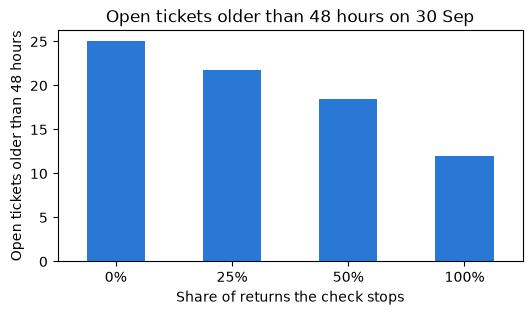

In [9]:
what_if.plot(kind="bar", x="check_stops", y="open_over_48h", color="#2a78d6", legend=False,
             figsize=(6, 3), title="Open tickets older than 48 hours on 30 Sep")
plt.xlabel("Share of returns the check stops")
plt.xticks(rotation=0)
plt.ylabel("Open tickets older than 48 hours")
plt.show()

If the check prevents half of the avoidable returns, tickets open for more than 48 hours go from 25 to
18.5, and all open tickets from 48 to 41.5. About 9,650 waiting hours are removed, which is 14% of the
total. Most of the gain comes from two reasons: settings problems and missing information.

### What the tool does not fix

Even if every avoidable return were prevented, 35 tickets would still be open, 12 of them for more than
48 hours. Two things are untouched: 52% more tickets are arriving, and a real engineering fix still
takes about 65 hours (that is the median of all fixes; a fix that needs only one trip takes about 57). Both need work outside this tool, and both are in the four-week plan.

## In short

| Question | Answer |
|---|---|
| Can we predict which tickets come back? | No. 56% against 59% for flagging everything |
| Can duplicates be caught automatically? | No. 17% against 14% with no rule |
| So what does the tool do? | Runs a checklist on every escalation, and shows known issues |
| How much could it help? | If half are prevented, old open tickets go from 25 to 18.5 |
| What is left? | More tickets arriving (+52%) and slow real fixes (about 65 hours) |
| How do we find the real effect? | Pilot it with a few agents and measure. The app logs every check for this |